# Customer Churn Prediction — Exploratory Data Analysis

**Goal:** understand who churns and why, before building a model that predicts it.

**Dataset:** IBM *Telco Customer Churn* — 7,043 customers of a telecom operator, 20 attributes and the `Churn` label.

**Contents**
1. Setup and data loading
2. Descriptive analysis (shape, types, missing values, statistics)
3. Visual analysis (target, contract, tenure, charges, correlations)
4. Preprocessing pipeline
5. Model comparison and explainability
6. Conclusions

## 1. Setup and data loading

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns

from src.data_loader import load_raw_data
from src.preprocessing import build_preprocessor, clean_data, split_data

# Colours: blue = retained, orange = churned (colour-blind safe pair)
RETAINED, CHURNED = "#2A78D6", "#EB6834"
COLORS = {"No": RETAINED, "Yes": CHURNED}

pio.renderers.default = "notebook_connected"
pio.templates.default = "plotly_white"
sns.set_theme(style="whitegrid", palette=[RETAINED, CHURNED])
pd.set_option("display.max_columns", 30)

In [2]:
raw = load_raw_data()   # downloads the CSV on first run
raw.head()

2026-11-10 13:25:09 | INFO     | src.data_loader | Loaded dataset: 7043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Descriptive analysis
### 2.1 Shape and types

In [3]:
print(f"Rows: {raw.shape[0]:,}  |  Columns: {raw.shape[1]}")
raw.dtypes.to_frame("dtype").T

Rows: 7,043  |  Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


`TotalCharges` is stored as text although it is a number: a sign of hidden missing values.

### 2.2 Missing values

In [4]:
explicit_nan = raw.isna().sum().sum()
blank_total = (raw["TotalCharges"].astype(str).str.strip() == "").sum()
print(f"Explicit NaN values: {explicit_nan}")
print(f"Blank TotalCharges:  {blank_total}")

raw.loc[raw["TotalCharges"].astype(str).str.strip() == "", ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Explicit NaN values: 0
Blank TotalCharges:  11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


The 11 blank `TotalCharges` all belong to customers with `tenure = 0`: they have not been billed yet.
They are not errors — the pipeline fills them with `tenure × MonthlyCharges` (= 0).

### 2.3 Statistics

In [5]:
df = clean_data(raw)
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

2026-11-10 13:25:09 | INFO     | src.preprocessing | TotalCharges: 11 missing values (new customers)


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


In [6]:
df.describe(include="object").T

,count,unique,top,freq
gender,7043,2,Male,3555
SeniorCitizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [7]:
print(f"Duplicated customer IDs: {raw['customerID'].duplicated().sum()}")
churn_rate = (df["Churn"] == "Yes").mean()
print(f"Churn rate: {churn_rate:.1%}")

Duplicated customer IDs: 0
Churn rate: 26.5%


## 3. Visual analysis
### 3.1 Churn distribution

In [8]:
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
fig = go.Figure(go.Pie(
    labels=["Retained", "Churned"], values=counts.values, hole=0.6, sort=False,
    marker=dict(colors=[RETAINED, CHURNED], line=dict(color="white", width=2)),
    textinfo="label+percent", textposition="outside",
))
fig.update_layout(title="Churn distribution", showlegend=False, height=380)
fig.show()

**26.5% of customers churned.** The classes are imbalanced: accuracy alone would be misleading
(a model predicting "nobody leaves" would reach 73.5%), so ROC AUC, recall and F1 are the metrics to watch.

### 3.2 Churn vs contract

In [9]:
def churn_rate_by(column: str) -> pd.DataFrame:
    out = (df.assign(churned=df["Churn"].eq("Yes"))
             .groupby(column).agg(churn_rate=("churned", "mean"), customers=("churned", "size"))
             .reset_index())
    out["churn_rate"] = (100 * out["churn_rate"]).round(1)
    return out

by_contract = churn_rate_by("Contract")
fig = px.bar(by_contract, x="Contract", y="churn_rate", text="churn_rate",
             hover_data=["customers"], color_discrete_sequence=[RETAINED],
             title="Churn rate by contract type")
fig.update_traces(texttemplate="%{text:.0f}%", textposition="outside", marker_cornerradius=4)
fig.update_layout(yaxis_title="Churn rate (%)", xaxis_title="", height=400)
fig.show()
by_contract

,Contract,churn_rate,customers
0,Month-to-month,42.7,3875
1,One year,11.3,1473
2,Two year,2.8,1695


Month-to-month customers churn at **43%**, versus 11% (one year) and 3% (two years).
Commitment is the strongest structural protection against churn.

### 3.3 Churn vs tenure

In [10]:
fig = px.histogram(df, x="tenure", color="Churn", nbins=36, barmode="stack",
                   color_discrete_map=COLORS, category_orders={"Churn": ["No", "Yes"]},
                   title="Tenure distribution by churn status")
fig.update_traces(marker_line_color="white", marker_line_width=1.5)
fig.update_layout(xaxis_title="Tenure (months)", yaxis_title="Customers", height=400, legend_title="Churn")
fig.show()

In [11]:
df["TenureGroup"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-1 year", "1-2 years", "2-4 years", "4+ years"])
by_tenure = churn_rate_by("TenureGroup")
fig = px.bar(by_tenure, x="TenureGroup", y="churn_rate", text="churn_rate", color_discrete_sequence=[RETAINED],
             title="Churn rate by tenure stage")
fig.update_traces(texttemplate="%{text:.0f}%", textposition="outside", marker_cornerradius=4)
fig.update_layout(yaxis_title="Churn rate (%)", xaxis_title="", height=380)
fig.show()

Churn is an **early-life problem**: almost half of first-year customers leave, and the rate falls
steadily afterwards.

### 3.4 Churn vs monthly charges

In [12]:
fig = px.violin(df, x="Churn", y="MonthlyCharges", color="Churn", box=True, points=False,
                color_discrete_map=COLORS, category_orders={"Churn": ["No", "Yes"]},
                title="Monthly charges by churn status")
fig.update_layout(yaxis_title="Monthly charges ($)", xaxis_title="Churn", showlegend=False, height=420)
fig.show()
df.groupby("Churn")["MonthlyCharges"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


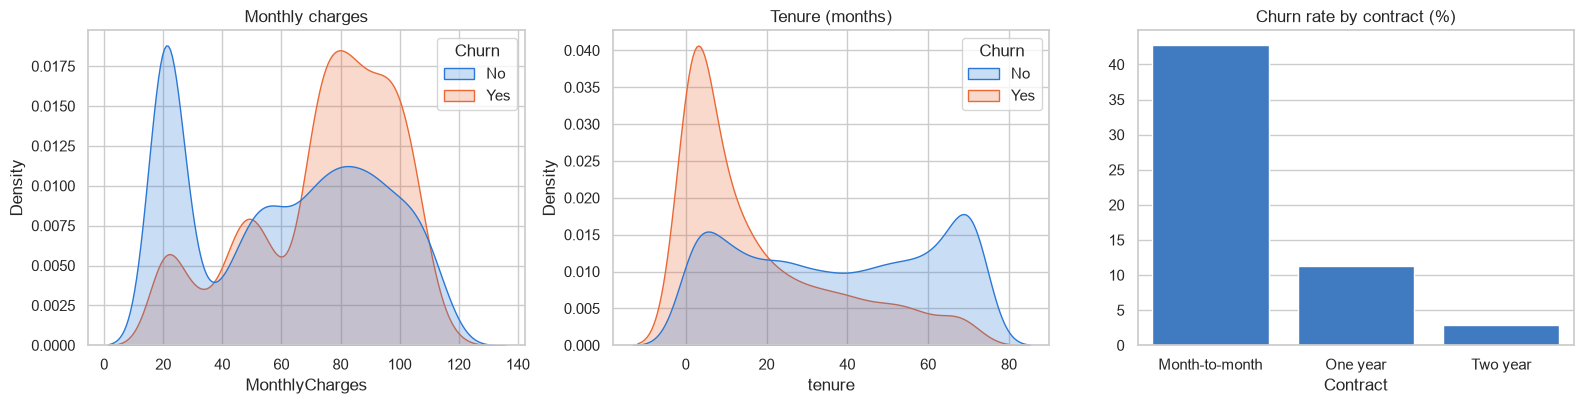

In [13]:
# Static version (renders on GitHub, where interactive Plotly charts do not)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"], fill=True, common_norm=False, ax=axes[0])
axes[0].set_title("Monthly charges")
sns.kdeplot(data=df, x="tenure", hue="Churn", hue_order=["No", "Yes"], fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("Tenure (months)")
sns.barplot(data=df.assign(churned=df["Churn"].eq("Yes") * 100), x="Contract", y="churned", color=RETAINED, errorbar=None, ax=axes[2])
axes[2].set_title("Churn rate by contract (%)"); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()

Churned customers pay more on average (median ≈ $80 vs ≈ $64). The retained group has a large
mass of low bills (~$20): phone-only customers, who rarely leave.

### 3.5 Other segments

In [14]:
segments = ["InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "SeniorCitizen", "PaperlessBilling"]
rows = []
for column in segments:
    part = churn_rate_by(column).rename(columns={column: "value"})
    part.insert(0, "feature", column)
    rows.append(part)
segment_table = pd.concat(rows, ignore_index=True)

fig = px.bar(segment_table, x="churn_rate", y="value", facet_col="feature", facet_col_wrap=3,
             orientation="h", text="churn_rate", color_discrete_sequence=[RETAINED],
             title="Churn rate (%) across customer segments", height=560)
fig.update_traces(texttemplate="%{text:.0f}%", textposition="outside", marker_cornerradius=4)
fig.update_yaxes(matches=None, showticklabels=True, title="")
fig.update_xaxes(title="", range=[0, 60])
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

### 3.6 Correlation matrix

In [15]:
encoded = df.drop(columns=["TenureGroup"]).copy()
encoded["Churn"] = encoded["Churn"].eq("Yes").astype(int)
binary = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]
for column in binary:
    encoded[column] = encoded[column].isin(["Yes", "Male"]).astype(int)
encoded = pd.get_dummies(encoded, columns=["Contract", "InternetService", "PaymentMethod"], dtype=int)
encoded = encoded.select_dtypes("number")
corr = encoded.corr().round(2)

# Diverging scale: blue = negative, neutral grey = 0, orange = positive
scale = [[0, RETAINED], [0.5, "#F1F1EF"], [1, CHURNED]]
fig = go.Figure(go.Heatmap(z=corr.values, x=corr.columns, y=corr.index, zmin=-1, zmax=1,
                           colorscale=scale, xgap=1, ygap=1, colorbar=dict(title="r"),
                           hovertemplate="%{y} × %{x}<br>r = %{z}<extra></extra>"))
fig.update_layout(title="Correlation matrix", height=720, yaxis_autorange="reversed")
fig.show()

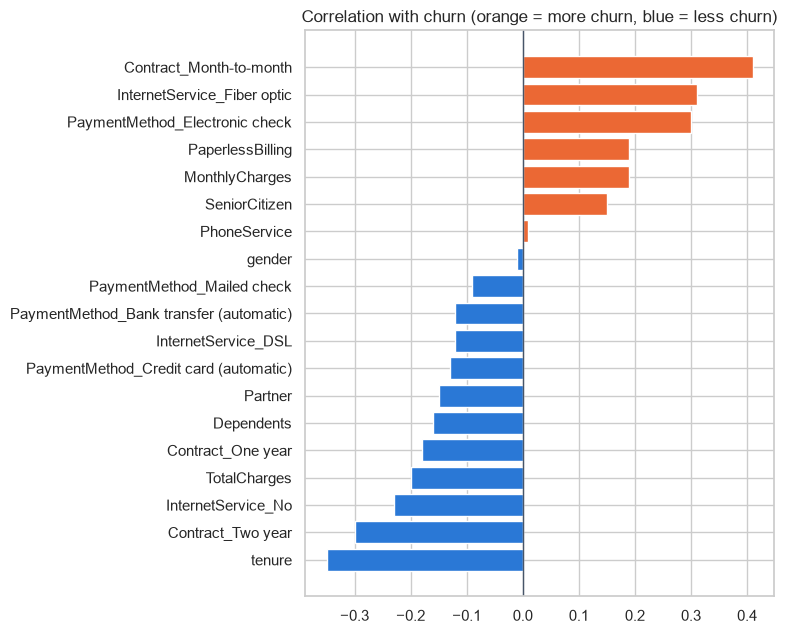

In [16]:
target_corr = corr["Churn"].drop("Churn").sort_values()
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(target_corr.index, target_corr.values, color=[CHURNED if v > 0 else RETAINED for v in target_corr.values])
ax.axvline(0, color="#475569", linewidth=1)
ax.set_title("Correlation with churn (orange = more churn, blue = less churn)")
plt.tight_layout(); plt.show()

**Reading:** month-to-month contracts, fiber optic and electronic checks are the strongest positive
correlates of churn; tenure and two-year contracts are the strongest protective factors.
`TotalCharges` is highly correlated with `tenure` (r ≈ 0.83) — it is essentially tenure × price.

## 4. Preprocessing pipeline

The same `Pipeline` is used for training and for the web app:

| Step | Columns | Transformation |
|---|---|---|
| Feature engineering | all | `AvgMonthlySpend`, `ChargeDelta`, `NumServices`, `TenureGroup` |
| Numeric | 6 | median imputation → `StandardScaler` |
| Binary | 6 | label (ordinal) encoding |
| Nominal | 11 | one-hot encoding |

In [17]:
X_train, X_test, y_train, y_test = split_data(raw)
preprocessor = build_preprocessor()
X_train_t = preprocessor.fit_transform(X_train)
print(f"Before: {X_train.shape}  →  after: {X_train_t.shape}")
preprocessor

2026-11-10 13:25:11 | INFO     | src.preprocessing | TotalCharges: 11 missing values (new customers)


2026-11-10 13:25:11 | INFO     | src.preprocessing | Split: 5634 train / 1409 test rows (churn rate 26.5% / 26.5%)


Before: (5634, 19)  →  after: (5634, 47)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
Name,Type,Value
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second ar

In [18]:
X_train_t.head(3).round(2)

,tenure,MonthlyCharges,TotalCharges,AvgMonthlySpend,ChargeDelta,NumServices,gender,SeniorCitizen,Partner,Dependents,PhoneService,PaperlessBilling,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_0-1 year,TenureGroup_1-2 years,TenureGroup_2-4 years,TenureGroup_4+ years
3738,0.10,-0.52,-0.26,-0.54,0.17,0.12,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3151,-0.71,0.34,-0.50,0.39,-0.55,-0.35,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4860,-0.79,-0.81,-0.75,-0.64,-1.57,0.12,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


## 5. Model comparison and explainability

The full training pipeline lives in `src/train.py` (`python -m src.train`). It cross-validates five
models, tunes the best one with `RandomizedSearchCV` and saves every artefact. Results of the last run:

In [19]:
from src.config import METADATA_PATH, METRICS_PATH
from src.evaluate import load_comparison_table, load_json, load_roc_curves

if not METRICS_PATH.exists():          # first run: train the models
    from src.train import run_training
    run_training()

table = load_comparison_table()
metadata = load_json(METADATA_PATH)
print(f"Best model: {metadata['best_model']} (selected on cross-validated ROC AUC)")
table.drop(columns=["cv_roc_auc_std"]).style.format("{:.3f}").highlight_max(axis=0, props="font-weight:bold")

Best model: Logistic Regression (selected on cross-validated ROC AUC)


,accuracy,precision,recall,f1,roc_auc,cv_roc_auc,fit_seconds
model,,,,,,,
Logistic Regression,0.799,0.653,0.519,0.578,0.842,0.846,0.123
Gradient Boosting,0.801,0.665,0.505,0.574,0.843,0.846,1.062
XGBoost,0.798,0.653,0.508,0.571,0.840,0.843,0.413
Random Forest,0.797,0.652,0.505,0.569,0.839,0.841,1.298
LightGBM,0.796,0.646,0.513,0.572,0.839,0.839,0.257


In [20]:
palette = ["#2A78D6", "#EB6834", "#1BAF7A", "#EDA100", "#E87BA4"]
fig = go.Figure()
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", name="Random guess", line=dict(dash="dash", color="#94A3B8")))
for color, (name, curve) in zip(palette, load_roc_curves().items()):
    fig.add_trace(go.Scatter(x=curve["fpr"], y=curve["tpr"], mode="lines", line=dict(color=color, width=2),
                             name=f"{name} (AUC {table.loc[name, 'roc_auc']:.3f})"))
fig.update_layout(title="ROC curves (test set)", xaxis_title="False positive rate", yaxis_title="True positive rate",
                  height=480, legend=dict(x=0.98, y=0.04, xanchor="right", yanchor="bottom"))
fig.show()

In [21]:
print(f"Decision threshold tuned on out-of-fold predictions: {metadata['decision_threshold']:.2f}")
pd.DataFrame({"threshold 0.50": metadata["final_metrics"],
              f"threshold {metadata['decision_threshold']:.2f}": metadata["threshold_metrics"]}).round(3)

Decision threshold tuned on out-of-fold predictions: 0.29


,threshold 0.50,threshold 0.29
accuracy,0.799,0.749
precision,0.653,0.519
recall,0.519,0.765
f1,0.578,0.618
roc_auc,0.842,0.842


### SHAP — what drives the predictions?

In [22]:
import joblib
import shap
from src.config import SHAP_PATH
from src.explain import summary_plot

bundle = joblib.load(SHAP_PATH)
explanation = shap.Explanation(values=bundle["values"], base_values=bundle["base_values"], data=bundle["data"],
                               display_data=bundle["display_data"], feature_names=bundle["feature_names"])
summary_plot(explanation, max_display=14);

In [23]:
index = int(np.argmax(bundle["probabilities"]))   # highest-risk customer of the sample
print(f"Churn probability: {bundle['probabilities'][index]:.0%}")
shap.plots.waterfall(explanation[index], max_display=10)

Churn probability: 86%


## 6. Conclusions

**What the data says**
- **Contract** — month-to-month customers churn at 43% vs 3% on two-year contracts.
- **Tenure** — churn is an early-life problem: ~47% in the first year, under 10% after four years.
- **Price and product** — churners pay more; fiber-optic customers are over-represented among them.
- **Payment** — electronic-check payers churn far more than customers on automatic payment.
- **Support** — customers without tech support or online security leave more often.

**What the model adds**
- The five models perform within one AUC point (≈ 0.84): the signal is mostly linear, so the simplest,
  most interpretable model is a sound choice.
- Lowering the decision threshold from 0.50 to the tuned value catches about three churners in four,
  at the cost of more false alarms — a trade-off to set with the retention team.

**Recommended actions**
1. Strengthen onboarding during the first 12 months.
2. Incentivise month-to-month customers to commit to a one-year contract.
3. Review fiber pricing / quality of service and bundle tech support for at-risk customers.
4. Nudge electronic-check payers towards automatic payment.